# Day 2 - Supervised learning practical tasks
***
These tasks cover linear regression, logistic regression, decision trees, model evaluation and regularization.

## Regression models

You will use [Advertising](https://www.kaggle.com/purbar/advertising-data) Dataset. The dataset contains statistics about the sales of a product in 200 different markets, together with advertising budgets in each of these markets for different media channels: TV, radio and newspaper.
#### Your task will be to:
1. Write evaluation functions (MAE, MSE, SSE, RMSE, MAPE, R2).
2. Analyze the correlation matrix.
3. Predict sales values using linear regression.
4. Evaluate model with written statistical explanatory variables.
5. Perform cross-validation (k-fold).
6. Compare your regression model to a reduced model by removing one of the features.
7. Compare your regression model to regularization models.

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

In [22]:
import pandas as pd
import numpy as np

### 1. Create statistical evaluation functions for regression models

#### 1.1 Create a function that calculates mean absolute error (MAE)

\begin{equation}
MAE = \frac{1}{n} \sum_{i=1}^{n} \left| y_i - \hat{y}_i\right|
\end{equation}

In [11]:
def mae(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return np.mean(np.abs(y_true - y_pred))

#### 1.2 Create a function that calculates mean squared error (MSE)

\begin{equation}
MSE = \frac{1}{n}\cdot SSE
\end{equation}

\begin{equation}
SSE = \sum_{i=1}^n(y_i - \hat{y}_i)^2
\end{equation}

In [12]:
def mse(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return np.mean((y_true - y_pred) ** 2)

#### 1.3 Create a function that calculates root mean squared error (RMSE)

\begin{equation}
RMSE = \sqrt{MSE}
\end{equation}

In [13]:
def rmse(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

#### 1.4 Create a function that calculates mean absolute percentage error (MAPE)

\begin{equation}
MAPE = \frac{100}{n} \sum_{i=1}^n \left| \frac{y_i - \hat{y}_i}{y_i} \right|
\end{equation}

In [14]:
def mape(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

#### 1.5 Create a function that calculates coefficient of determination $R^2$ using formula

\begin{equation}
R^2 = \frac{SST-SSE}{SST}
\end{equation}

\begin{equation}
SST = \sum_{i=1}^n (y_i - \bar{y})^2
\end{equation}


In [15]:
def r2(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

### 2 Use Linear regression model to make predictions and evaluate it with above developed functions. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling - split the data in target variable and features.

In [23]:
# Load the Advertising dataset. Keep the CSV in the same folder as this notebook.
advertising = pd.read_csv("advertising.csv")

# Remove the index column if it was saved in the CSV.
advertising = advertising.loc[:, ~advertising.columns.str.match(r"^Unnamed")]

display(advertising.head())
print("Dataset shape:", advertising.shape)
print(advertising.isnull().sum())

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


Dataset shape: (200, 4)
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64


In [24]:
# Target variable and predictor features
target_column = "Sales"
X = advertising.drop(columns=[target_column])
y = advertising[target_column]

print("Feature columns:", X.columns.tolist())
print("Target:", target_column)
print("X shape:", X.shape, "| y shape:", y.shape)

Feature columns: ['TV', 'Radio', 'Newspaper']
Target: Sales
X shape: (200, 3) | y shape: (200,)


In [25]:
advertising.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns


Matplotlib is building the font cache; this may take a moment.


,TV,Radio,Newspaper,Sales
TV,1.000000,0.054809,0.056648,0.782224
Radio,0.054809,1.000000,0.354104,0.576223
Newspaper,0.056648,0.354104,1.000000,0.228299
Sales,0.782224,0.576223,0.228299,1.000000


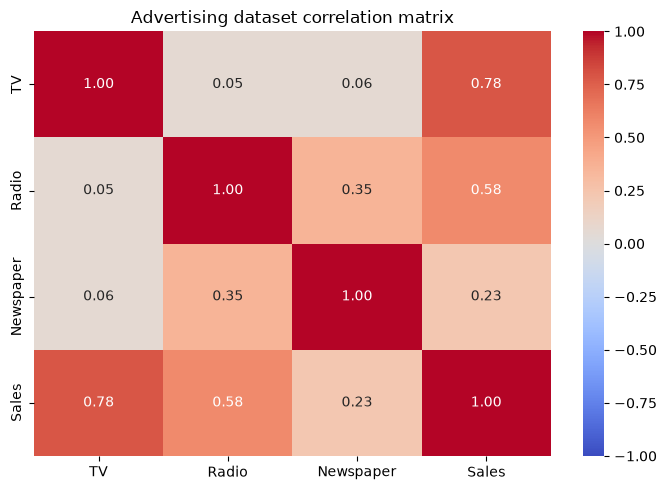

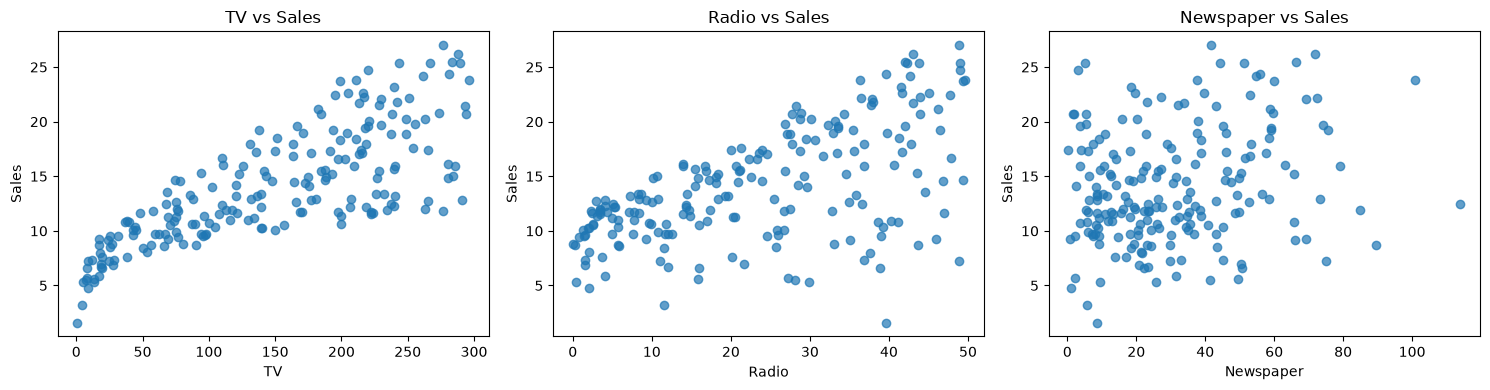

In [30]:
# Correlation matrix
corr = advertising.corr(numeric_only=True)
display(corr)

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Advertising dataset correlation matrix")
plt.tight_layout()
plt.show()

# Scatter plots to inspect the relationship between each channel and Sales.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, ["TV", "Radio", "Newspaper"]):
    ax.scatter(advertising[feature], advertising["Sales"], alpha=0.7)
    ax.set_xlabel(feature)
    ax.set_ylabel("Sales")
    ax.set_title(f"{feature} vs Sales")
plt.tight_layout()
plt.show()



In [31]:
# The correlation matrix and pair plots help show how each advertising channel relates to Sales.
sales_correlations = corr["Sales"].drop("Sales").sort_values(ascending=False)
print("Correlation with Sales:")
print(sales_correlations)
print("\nObservation: use the displayed correlations and scatter plots to identify which channel has the strongest linear relationship with Sales.")


Correlation with Sales:
TV           0.782224
Radio        0.576223
Newspaper    0.228299
Name: Sales, dtype: float64

Observation: use the displayed correlations and scatter plots to identify which channel has the strongest linear relationship with Sales.


#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler).

In [34]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [35]:
# Hold out 33% for testing; fit the scaler on training data only to avoid data leakage.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=17
)
scaler_reg = StandardScaler()
X_train_scaled = scaler_reg.fit_transform(X_train)
X_test_scaled = scaler_reg.transform(X_test)

print("Train shapes:", X_train_scaled.shape, y_train.shape)
print("Test shapes:", X_test_scaled.shape, y_test.shape)


Train shapes: (134, 3) (134,)
Test shapes: (66, 3) (66,)


#### 2.4 Fit linear regression model, generate predictions and print regression coefficients $b_0$ and $b_1$.

In [37]:
from sklearn.linear_model import LinearRegression

In [38]:

linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)
y_pred = linear_model.predict(X_test_scaled)

print("Intercept (b0):", linear_model.intercept_)
print("Coefficients (b1 values):")
for feature, coefficient in zip(X.columns, linear_model.coef_):
    print(f"  {feature}: {coefficient:.4f}")


Intercept (b0): 14.022388059701495
Coefficients (b1 values):
  TV: 3.9675
  Radio: 2.8816
  Newspaper: -0.0734


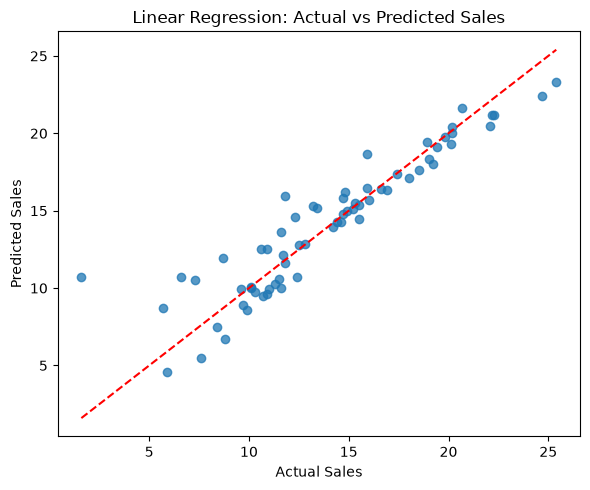

In [39]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.75)
limits = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(limits, limits, "r--")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Linear Regression: Actual vs Predicted Sales")
plt.tight_layout()
plt.show()



#### 2.5 Evaluate created model with above functions

In [41]:
def sse(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.sum((y_true - y_pred) ** 2)

In [44]:
def r_squared(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)

    return 1 - (ss_res / ss_tot)

In [45]:
print(f"MAE:  {mae(y_test, y_pred):.4f}")
print(f"MSE:  {mse(y_test, y_pred):.4f}")
print(f"SSE:  {sse(y_test, y_pred):.4f}")
print(f"RMSE: {rmse(y_test, y_pred):.4f}")
print(f"MAPE: {mape(y_test, y_pred):.2f}%")
print(f"R²:   {r_squared(y_test, y_pred):.4f}")


MAE:  1.2415
MSE:  3.4726
SSE:  229.1936
RMSE: 1.8635
MAPE: 18.64%
R²:   0.8515


#### 2.6 Perform k-fold cross-validation $(k=10)$ and print the mean $R^2$ score to get an overall performance metric.

Please use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [r2](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules) score.

In [47]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

In [48]:
cv_r2 = cross_val_score(
    LinearRegression(), X_train_scaled, y_train, cv=10, scoring="r2"
)
print("10-fold R² scores:", np.round(cv_r2, 4))
print(f"Mean 10-fold R²: {cv_r2.mean():.4f}")


10-fold R² scores: [0.9517 0.8678 0.9233 0.8526 0.909  0.8694 0.9126 0.8187 0.9298 0.948 ]
Mean 10-fold R²: 0.8983


#### 2.7. Drop one of the three variables (TV, Radio or Newspaper) and create another model, evaluate it and compare to the first model.

In [49]:
# Reduced model: remove Newspaper and compare it with the full model.
reduced_features = [column for column in X.columns if column != "Newspaper"]
X_train_reduced = X_train[reduced_features]
X_test_reduced = X_test[reduced_features]

scaler_reduced = StandardScaler()
X_train_reduced_scaled = scaler_reduced.fit_transform(X_train_reduced)
X_test_reduced_scaled = scaler_reduced.transform(X_test_reduced)

reduced_model = LinearRegression()
reduced_model.fit(X_train_reduced_scaled, y_train)
y_pred_reduced = reduced_model.predict(X_test_reduced_scaled)

print("Full model:")
print(f"  MSE = {mse(y_test, y_pred):.4f}, R² = {r_squared(y_test, y_pred):.4f}")
print("Reduced model (without Newspaper):")
print(f"  MSE = {mse(y_test, y_pred_reduced):.4f}, R² = {r_squared(y_test, y_pred_reduced):.4f}")

Full model:
  MSE = 3.4726, R² = 0.8515
Reduced model (without Newspaper):
  MSE = 3.4587, R² = 0.8521


In [50]:
comparison = pd.DataFrame({
    "Model": ["Full model (TV, Radio, Newspaper)", "Reduced model (TV, Radio)"],
    "MSE": [mse(y_test, y_pred), mse(y_test, y_pred_reduced)],
    "RMSE": [rmse(y_test, y_pred), rmse(y_test, y_pred_reduced)],
    "R²": [r_squared(y_test, y_pred), r_squared(y_test, y_pred_reduced)]
})
display(comparison)


,Model,MSE,RMSE,R²
0,"Full model (TV, Radio, Newspaper)",3.472630,1.863499,0.851537
1,"Reduced model (TV, Radio)",3.458741,1.859769,0.852131


### 3. Use regularization models with regularization strength `alpha=1` and compare $MSE$ values with previous models.

#### 3.1 Lasso regression

In [52]:
from sklearn.linear_model import Lasso

In [53]:
lasso = Lasso(alpha=1.0, max_iter=10000)
lasso.fit(X_train_scaled, y_train)
y_pred_lasso = lasso.predict(X_test_scaled)
print("Lasso MSE:", mse(y_test, y_pred_lasso))
print("Lasso coefficients:", dict(zip(X.columns, lasso.coef_)))

Lasso MSE: 4.911579294712751
Lasso coefficients: {'TV': np.float64(3.061959204016913), 'Radio': np.float64(1.962026340065606), 'Newspaper': np.float64(0.0)}


#### 3.2 Ridge regression

In [55]:
from sklearn.linear_model import Ridge

In [56]:
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train)
y_pred_ridge = ridge.predict(X_test_scaled)
print("Ridge MSE:", mse(y_test, y_pred_ridge))
print("Ridge coefficients:", dict(zip(X.columns, ridge.coef_)))

Ridge MSE: 3.4768894774722394
Ridge coefficients: {'TV': np.float64(3.9389936772300795), 'Radio': np.float64(2.8599640590273547), 'Newspaper': np.float64(-0.062182548689200784)}


#### 3.3 Elastic net regression

Use any `l1_ratio` of your choice.


In [58]:
from sklearn.linear_model import ElasticNet

In [59]:
elastic_net = ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=10000)
elastic_net.fit(X_train_scaled, y_train)
y_pred_elastic = elastic_net.predict(X_test_scaled)
print("Elastic Net MSE:", mse(y_test, y_pred_elastic))
print("Elastic Net coefficients:", dict(zip(X.columns, elastic_net.coef_)))

regression_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Lasso (alpha=1)", "Ridge (alpha=1)", "Elastic Net (alpha=1)"],
    "MSE": [mse(y_test, y_pred), mse(y_test, y_pred_lasso),
            mse(y_test, y_pred_ridge), mse(y_test, y_pred_elastic)],
    "RMSE": [rmse(y_test, y_pred), rmse(y_test, y_pred_lasso),
             rmse(y_test, y_pred_ridge), rmse(y_test, y_pred_elastic)],
    "R²": [r_squared(y_test, y_pred), r_squared(y_test, y_pred_lasso),
           r_squared(y_test, y_pred_ridge), r_squared(y_test, y_pred_elastic)]
})
display(regression_comparison.sort_values("MSE"))


Elastic Net MSE: 6.8438833201041085
Elastic Net coefficients: {'TV': np.float64(2.3939745905792056), 'Radio': np.float64(1.689074626968126), 'Newspaper': np.float64(0.014894890312050747)}


,Model,MSE,RMSE,R²
0,Linear Regression,3.472630,1.863499,0.851537
2,Ridge (alpha=1),3.476889,1.864642,0.851355
1,Lasso (alpha=1),4.911579,2.216208,0.790019
3,Elastic Net (alpha=1),6.843883,2.616082,0.707408


#### 3.4 Make conclusions

Conclusions
1. As we can see that linear regression was used to predict sales based on TV,Radio and newspaper advertising spending 
2. soo when we have done the correlation analysis we get to know that TV ads were the strongest relationship with the sales followed by radio annd newspaper ads 
3. Lasso, Ridge, and Elastic Net regression were tested to compare regularized models with standard Linear Regression.
4. The models were evaluated using MAE, MSE, SSE, RMSE, and R2. Lower error values and a higher R2 generally indicate better predictive performance.
5. The model with the lowest test MSE performed best among the tested models on the test dataset. Regularization does not always improve performance, so the results should guide the final choice.
6. Overall, this practical task demonstrated how to train, evaluate, and compare regression models using Python and Scikit-learn.

## Classification models

You will use [Diabetes](https://www.kaggle.com/uciml/pima-indians-diabetes-database) dataset. The dataset includes data from 768 women with several medical predictor variables and one target variable. The classification goal is to predict whether or not the patients in the dataset have diabetes.
#### Your task will be to:
1. Write evaluation functions (Accuracy, Precision, Recall, F1).
2. Predict whether or not a patient has diabetes using Logistic regression and Decision Tree Classification models
3. Evaluate both models with written statistical explanatory variables
4. Draw ROC curve and compute AUC
5. Perform cross-validation (k-fold)
6. Analyze the results

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

### 1. Write statistical evaluation functions for classification models

#### 1.1 Create a function that calculates accuracy

\begin{equation}
Accuracy = \frac{True Positive + True Negative}{True Positive + True Negative + False Positive + False Negative}
\end{equation}

In [60]:
def classification_accuracy(y_true, y_pred):
    return accuracy_score(y_true, y_pred)


#### 1.2 Create a function that calculates precision

\begin{equation}
Precision = \frac{True Positive}{True Positive + False Positive}
\end{equation}

In [61]:
def classification_precision(y_true, y_pred):
    return precision_score(y_true, y_pred, zero_division=0)

#### 1.3  Create a function that calculates recall

\begin{equation}
Recall = \frac{True Positive}{True Positive + False Negative}
\end{equation}

In [62]:
def classification_recall(y_true, y_pred):
    return recall_score(y_true, y_pred, zero_division=0)


#### 1.4 Create a function that calculates $F1$ - score

\begin{equation}
F1 = 2\cdot \frac{Precision \cdot Recall}{Precision + Recall}
\end{equation}

In [63]:
def classification_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, zero_division=0)

### 2. Use logistic regression to make prediction and evaluate it with above developed functions. Compute ROC and compute AUC. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling. Split the data in target variable and features.

Prepare dataset to use it for modelling (you should also replace 0 values in columns `Glucose`, `BloodPressure`,`SkinThickness`,`Insulin`,`BMI` with mean values).

In [64]:
diabetes = pd.read_csv("diabetes.csv")
# In this dataset, zero is used as a missing-value placeholder in these columns.
zero_missing_columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
for column in zero_missing_columns:
    diabetes[column] = diabetes[column].replace(0, np.nan)
    diabetes[column] = diabetes[column].fillna(diabetes[column].mean())

display(diabetes.head())
print("Dataset shape:", diabetes.shape)
print("Remaining missing values:", int(diabetes.isnull().sum().sum()))

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.00000,155.548223,33.6,0.627,50,1
1,1,85.0,66.0,29.00000,155.548223,26.6,0.351,31,0
2,8,183.0,64.0,29.15342,155.548223,23.3,0.672,32,1
3,1,89.0,66.0,23.00000,94.000000,28.1,0.167,21,0
4,0,137.0,40.0,35.00000,168.000000,43.1,2.288,33,1


Dataset shape: (768, 9)
Remaining missing values: 0


#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

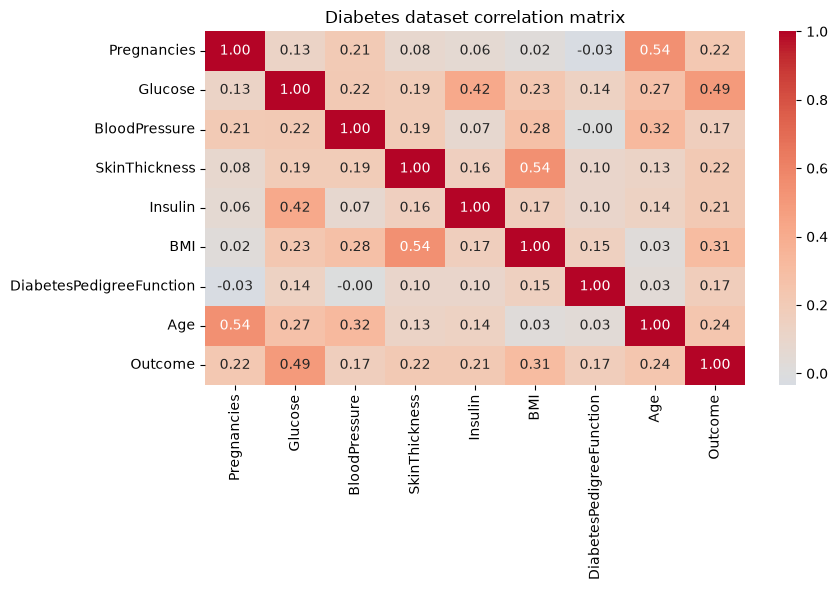

Correlation with Outcome:
Glucose                     0.492928
BMI                         0.311924
Age                         0.238356
Pregnancies                 0.221898
SkinThickness               0.215299
Insulin                     0.214411
DiabetesPedigreeFunction    0.173844
BloodPressure               0.166074
Name: Outcome, dtype: float64


In [65]:
diabetes_corr = diabetes.corr(numeric_only=True)
plt.figure(figsize=(9, 6))
sns.heatmap(diabetes_corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Diabetes dataset correlation matrix")
plt.tight_layout()
plt.show()

print("Correlation with Outcome:")
print(diabetes_corr["Outcome"].drop("Outcome").sort_values(ascending=False))

#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

In [66]:
X_diabetes = diabetes.drop(columns=["Outcome"])
y_diabetes = diabetes["Outcome"]

X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(
    X_diabetes, y_diabetes, test_size=0.33, random_state=17, stratify=y_diabetes
)

scaler_diabetes = StandardScaler()
X_train_d_scaled = scaler_diabetes.fit_transform(X_train_d)
X_test_d_scaled = scaler_diabetes.transform(X_test_d)

print("Train shapes:", X_train_d_scaled.shape, y_train_d.shape)
print("Test shapes:", X_test_d_scaled.shape, y_test_d.shape)

Train shapes: (514, 8) (514,)
Test shapes: (254, 8) (254,)


#### 2.4 Fit logistic regression model, generate predictions

In [68]:
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression(max_iter=1000, random_state=17)
logreg.fit(X_train_d_scaled, y_train_d)
y_pred_log = logreg.predict(X_test_d_scaled)
y_prob_log = logreg.predict_proba(X_test_d_scaled)[:, 1]
print("First 10 predictions:", y_pred_log[:10])

First 10 predictions: [1 0 0 1 1 0 0 0 0 0]


#### 2.5 Create a confusion matrix and evaluate created model with above functions

In [72]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

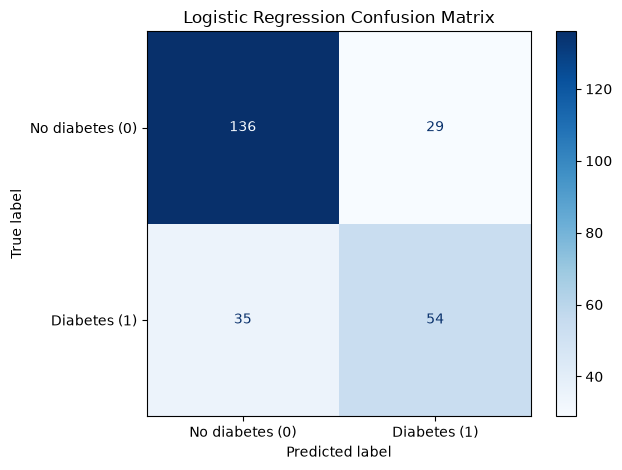

Accuracy:  0.7480
Precision: 0.6506
Recall:    0.6067
F1-score:  0.6279


In [73]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_log = confusion_matrix(y_test_d, y_pred_log)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_log, display_labels=["No diabetes (0)", "Diabetes (1)"])
disp.plot(cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

print(f"Accuracy:  {classification_accuracy(y_test_d, y_pred_log):.4f}")
print(f"Precision: {classification_precision(y_test_d, y_pred_log):.4f}")
print(f"Recall:    {classification_recall(y_test_d, y_pred_log):.4f}")
print(f"F1-score:  {classification_f1(y_test_d, y_pred_log):.4f}")

#### 2.6 Draw a ROC curve and compute Area Under the Curve (AUC)

You can use [roc_auc_score](http://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html) and [RocCurveDisplay.from_predictions](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.RocCurveDisplay.html#sklearn.metrics.RocCurveDisplay.from_predictions).
Check documentation for examples.
For roc_auc_score use predicted probabilities (`predict_proba`), not predicted values. This will align your AUC and ROC curve values.

`predict_proba()` method returns a two-dimensional array. For each instance the predicted class is the class with the maximum probability. To calculate AUC correctly, you need the probability of the positive class (second column, `[:, 1]`).

In [75]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay

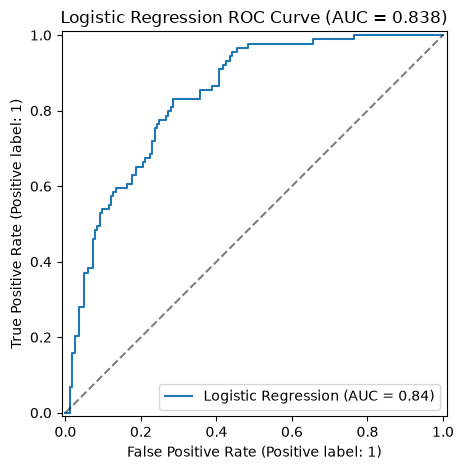

Logistic Regression AUC: 0.8385


In [76]:
auc_log = roc_auc_score(y_test_d, y_prob_log)
RocCurveDisplay.from_predictions(y_test_d, y_prob_log, name="Logistic Regression")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.title(f"Logistic Regression ROC Curve (AUC = {auc_log:.3f})")
plt.tight_layout()
plt.show()
print(f"Logistic Regression AUC: {auc_log:.4f}")

#### 2.7 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

Use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [accuracy](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules). Feed your scaled X train and y train data.

In [77]:
cv_log = cross_val_score(
    LogisticRegression(max_iter=1000, random_state=17),
    X_train_d_scaled, y_train_d, cv=10, scoring="accuracy"
)
print("10-fold accuracy scores:", np.round(cv_log, 4))
print(f"Mean 10-fold accuracy: {cv_log.mean():.4f}")


10-fold accuracy scores: [0.7885 0.8269 0.7692 0.7692 0.7255 0.7451 0.7647 0.8235 0.6863 0.8039]
Mean 10-fold accuracy: 0.7703


### 3. Use Decision tree classification model to make predictions and evaluate it with above developed functions. Draw ROC curve and compute AUC. Perform k-fold cross-validation.

#### 3.1 Create classification tree object, fit model and generate predictions

In [79]:
from sklearn.tree import DecisionTreeClassifier

In [80]:
tree_model = DecisionTreeClassifier(random_state=17)
tree_model.fit(X_train_d_scaled, y_train_d)
y_pred_tree = tree_model.predict(X_test_d_scaled)
y_prob_tree = tree_model.predict_proba(X_test_d_scaled)[:, 1]
print("First 10 predictions:", y_pred_tree[:10])


First 10 predictions: [1 0 1 1 1 1 0 0 0 0]


#### 3.2 Evaluate created model with above functions

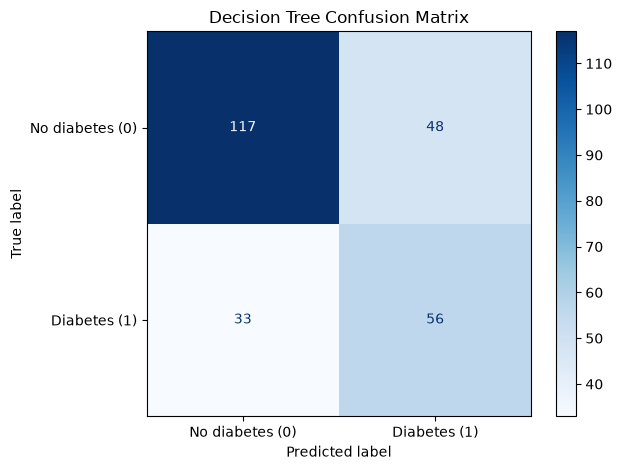

Accuracy:  0.6811
Precision: 0.5385
Recall:    0.6292
F1-score:  0.5803


In [81]:
cm_tree = confusion_matrix(y_test_d, y_pred_tree)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_tree, display_labels=["No diabetes (0)", "Diabetes (1)"])
disp.plot(cmap="Blues")
plt.title("Decision Tree Confusion Matrix")
plt.tight_layout()
plt.show()

print(f"Accuracy:  {classification_accuracy(y_test_d, y_pred_tree):.4f}")
print(f"Precision: {classification_precision(y_test_d, y_pred_tree):.4f}")
print(f"Recall:    {classification_recall(y_test_d, y_pred_tree):.4f}")
print(f"F1-score:  {classification_f1(y_test_d, y_pred_tree):.4f}")


#### 3.3 Draw a ROC curve and compute Area Under the Curve (AUC)

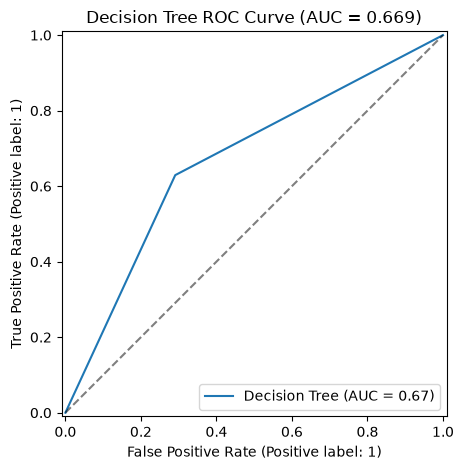

Decision Tree AUC: 0.6692


In [82]:
auc_tree = roc_auc_score(y_test_d, y_prob_tree)
RocCurveDisplay.from_predictions(y_test_d, y_prob_tree, name="Decision Tree")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.title(f"Decision Tree ROC Curve (AUC = {auc_tree:.3f})")
plt.tight_layout()
plt.show()
print(f"Decision Tree AUC: {auc_tree:.4f}")

#### 3.4 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

In [83]:
cv_tree = cross_val_score(
    DecisionTreeClassifier(random_state=17),
    X_train_d_scaled, y_train_d, cv=10, scoring="accuracy"
)
print("10-fold accuracy scores:", np.round(cv_tree, 4))
print(f"Mean 10-fold accuracy: {cv_tree.mean():.4f}")

10-fold accuracy scores: [0.8077 0.5962 0.6923 0.7692 0.6863 0.6667 0.7059 0.7255 0.6471 0.6471]
Mean 10-fold accuracy: 0.6944


#### 3.5 Make conclusions

CONCLUSIONS

Logistic Regression and Decision Tree were used to predict diabetes. Their performance was compared using different evaluation metrics. These models help identify possible diabetes cases, but their predictions should always be checked carefully.